# Laboratorio 5 - Ejercicio 3

## Configuración propia de nodos para el TSP

El ejercicio pide diseñar una configuración de nodos y resolver el problema del agente viajero para ella. Se usa el algoritmo genético del Ejercicio 1, que está en el archivo `ga_tsp.py` con las mismas funciones del cuaderno de ese ejercicio.

La configuración elegida es una cuadrícula de 8 por 8 ciudades con una separación de 10 unidades entre vecinas. Tiene 64 nodos. La ventaja de esta configuración es que se conoce el óptimo sin correr nada. Como el número de nodos es par, existe un recorrido que solo usa tramos de 10 unidades, y entonces la distancia mínima es $64 \times 10 = 640$. Cualquier recorrido que mida más de 640 es subóptimo. Además hay muchos recorridos óptimos distintos y también muchos casi óptimos, así que el algoritmo puede quedarse atascado en uno de estos últimos.

Las ciudades se numeran en orden revuelto, para que el número de una ciudad no diga nada de su lugar en la cuadrícula.

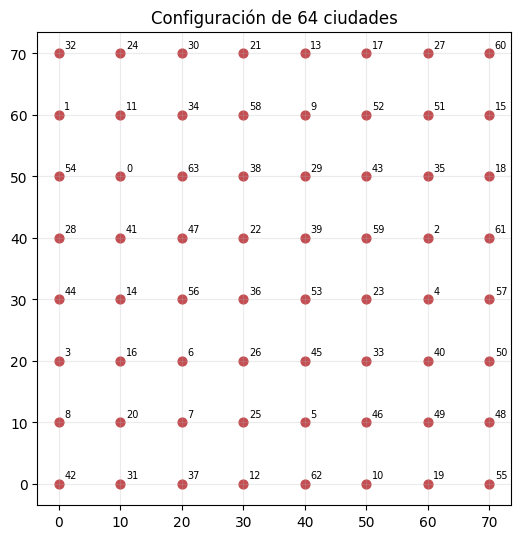

Ciudades: 64  Óptimo conocido: 640


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML

from ga_tsp import *

LADO, SEPARACION = 8, 10
OPTIMO = LADO * LADO * SEPARACION  # 640

g = np.arange(LADO) * SEPARACION
gx, gy = np.meshgrid(g, g)
cuadricula = np.column_stack([gx.ravel(), gy.ravel()]).astype(float)
ciudades = cuadricula[np.random.default_rng(2026).permutation(LADO * LADO)]
np.savetxt("cuadricula_8x8.csv", ciudades, fmt="%.0f", delimiter=",", header="x,y", comments="")

plt.figure(figsize=(5.5, 5.5))
plt.scatter(ciudades[:, 0], ciudades[:, 1], color=ROJO, s=40)
for i, (x, y) in enumerate(ciudades):
    plt.annotate(str(i), (x, y), textcoords="offset points", xytext=(4, 4), fontsize=7)
plt.title("Configuración de 64 ciudades")
plt.gca().set_aspect("equal")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("configuracion_cuadricula.png", dpi=200)
plt.show()
print("Ciudades:", len(ciudades), " Óptimo conocido:", OPTIMO)

### Explicación de esta parte

Se crean las 64 coordenadas, se revuelven los números de las ciudades y se guardan en el archivo `cuadricula_8x8.csv`. Ese archivo es la entrada del algoritmo, igual que en el Ejercicio 1. En la gráfica cada punto lleva el número de la ciudad.

## Corrida principal

Se usa una población de $N = 500$ recorridos, 2000 generaciones, selección por torneo con $k = 3$, 5 % de sobrevivientes por elitismo, 70 % de la población creada por cruce OX y 25 % creada por mutación por inversión. Son los valores que trae la función, salvo $N$ y `maxIter`, que se subieron porque son 64 ciudades.

In [2]:
PARAMETROS = dict(N=500, maxIter=2000, seleccion="torneo", k=3, s=0.05, c=0.70, m=0.25,
                  cruce="ox", mutacion="inversion")

best, D, historial = algoritmo_genetico_tsp("cuadricula_8x8.csv", semilla=0, **PARAMETROS)
inicial = historial["mejoras"][0][2]
ultima = historial["mejoras"][-1][0]
print("Mejor recorrido (best):")
print(best)
print(f"\nDistancia total D = {D:.2f}   óptimo = {OPTIMO}")
print(f"Mejor recorrido de la población inicial = {inicial:.2f}")
print(f"Reducción = {100 * (1 - D / inicial):.1f} %")
print(f"Última mejora en la generación {ultima} de {PARAMETROS['maxIter']}")

Mejor recorrido (best):
[31 42  8  3 44 28 41 14 56 47 63 38 29  9 58 34 11  0 54  1 32 24 30 21
 13 17 52 51 27 60 15 18 61  2 35 43 59 39 22 36 53 23 33 46 49 40  4 57
 50 48 55 19 10 62 12 25  5 45 26  6 16 20  7 37]

Distancia total D = 640.00   óptimo = 640
Mejor recorrido de la población inicial = 2252.19
Reducción = 71.6 %
Última mejora en la generación 399 de 2000


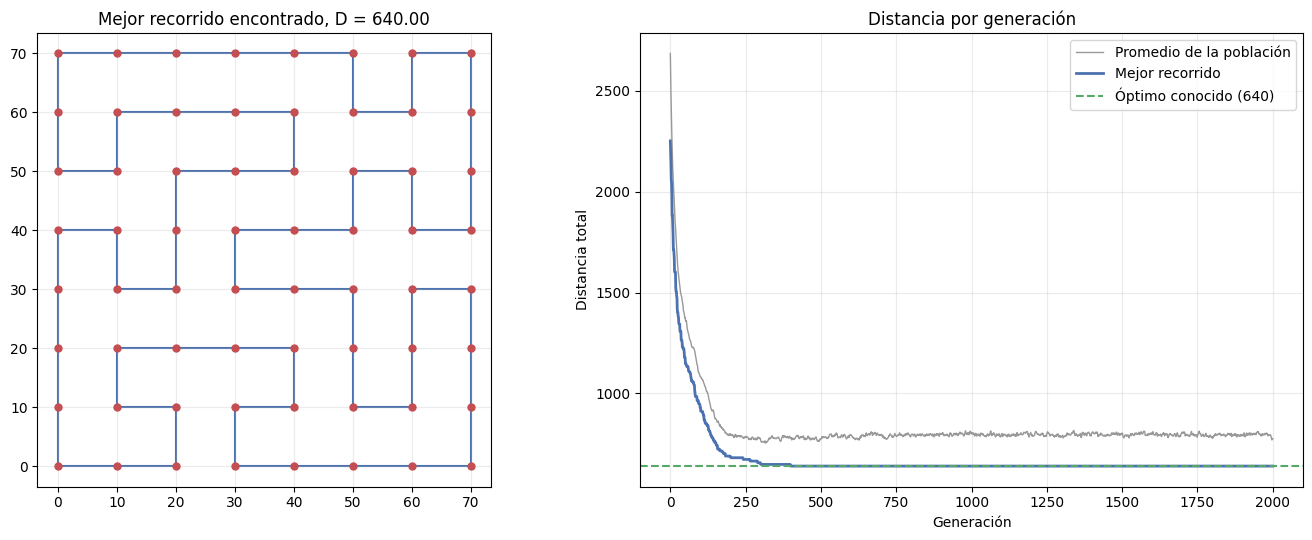

In [3]:
graficar_resultado(best, D, historial, optimo=OPTIMO)

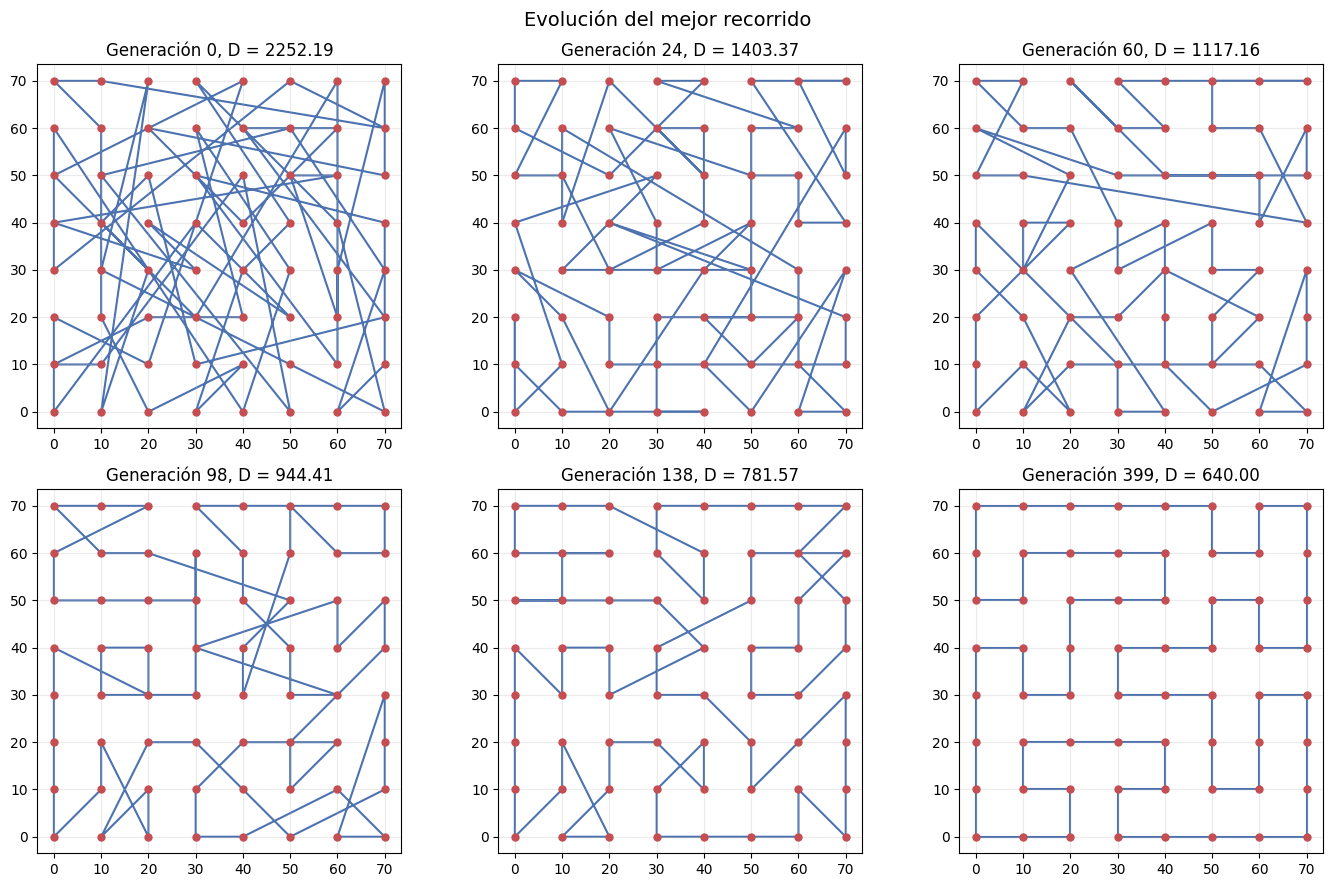

In [4]:
graficar_evolucion(historial)

In [5]:
# Se guardan las figuras para el informe
fig, (ax_ruta, ax_dist) = plt.subplots(1, 2, figsize=(14, 5.5))
dibujar_recorrido(ax_ruta, historial["posiciones"], best, f"Mejor recorrido encontrado, D = {D:.2f}")
dibujar_distancia(ax_dist, historial, OPTIMO)
plt.tight_layout()
plt.savefig("resultado_cuadricula.png", dpi=200)
plt.close(fig)

mejoras = historial["mejoras"]
elegidas = np.unique(np.linspace(0, len(mejoras) - 1, 6).astype(int))
fig, ejes = plt.subplots(2, 3, figsize=(14, 9))
for ax, indice in zip(ejes.ravel(), elegidas):
    generacion, recorrido, distancia = mejoras[indice]
    dibujar_recorrido(ax, historial["posiciones"], recorrido, f"Generación {generacion}, D = {distancia:.2f}")
fig.suptitle("Evolución del mejor recorrido", fontsize=14)
plt.tight_layout()
plt.savefig("evolucion_cuadricula.png", dpi=200)
plt.close(fig)

### Explicación de esta parte

La función devuelve el mejor recorrido `best` y su distancia `D`. Las gráficas muestran el recorrido final y los seis momentos de la corrida, y la curva de la distancia comparada con el óptimo de 640.

### Simulación

La celda crea la animación y la guarda en el archivo `evolucion_cuadricula.gif`.

In [6]:
animacion = animar_evolucion(historial, archivo="evolucion_cuadricula.gif", optimo=OPTIMO)
HTML(animacion.to_jshtml())

## Varias corridas y soluciones subóptimas

El resultado depende del azar. Se corre el algoritmo con 8 semillas y con dos tamaños de población, para ver cuántas veces llega al óptimo de 640 y cuántas se queda en una solución subóptima. La primera configuración usa $N = 300$ y 1500 generaciones. La segunda usa $N = 500$ y 2000 generaciones.

In [7]:
configuraciones = {
    "N = 300, 1500 generaciones": dict(PARAMETROS, N=300, maxIter=1500),
    "N = 500, 2000 generaciones": dict(PARAMETROS),
}
semillas = range(8)
corridas = {}
for nombre, parametros in configuraciones.items():
    corridas[nombre] = [algoritmo_genetico_tsp("cuadricula_8x8.csv", semilla=s, **parametros) for s in semillas]

print(f"{'Configuración':28s} {'Mejor':>7s} {'Mediana':>8s} {'Peor':>7s} {'Óptimos':>8s}")
for nombre, resultados in corridas.items():
    finales = np.array([D for _, D, _ in resultados])
    optimos = int((finales == OPTIMO).sum())
    print(f"{nombre:28s} {finales.min():7.2f} {np.median(finales):8.2f} {finales.max():7.2f} {optimos:5d} de 8")
print()
for nombre, resultados in corridas.items():
    print(nombre, [round(D, 2) for _, D, _ in resultados])

Configuración                  Mejor  Mediana    Peor  Óptimos
N = 300, 1500 generaciones    648.28   656.57  664.85     0 de 8
N = 500, 2000 generaciones    640.00   640.00  648.28     5 de 8

N = 300, 1500 generaciones [656.57, 656.57, 648.28, 656.57, 664.85, 656.57, 656.57, 656.57]
N = 500, 2000 generaciones [640.0, 640.0, 640.0, 640.0, 648.28, 640.0, 648.28, 648.28]


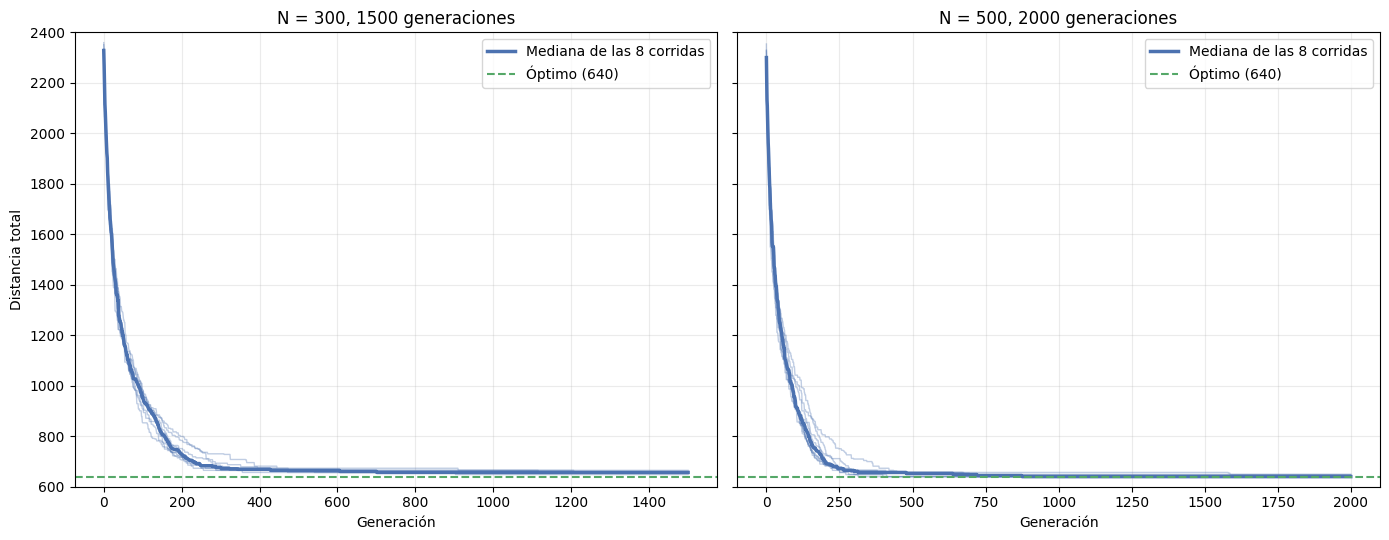

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, (nombre, resultados) in zip(ejes, corridas.items()):
    for _, _, h in resultados:
        ax.plot(h["mejor"], color=AZUL, alpha=0.35, linewidth=1)
    mediana = np.median([h["mejor"] for _, _, h in resultados], axis=0)
    ax.plot(mediana, color=AZUL, linewidth=2.5, label="Mediana de las 8 corridas")
    ax.axhline(OPTIMO, color=VERDE, linestyle="--", label=f"Óptimo ({OPTIMO})")
    ax.set_title(nombre)
    ax.set_xlabel("Generación")
    ax.set_ylim(600, 2400)
    ax.grid(alpha=0.25)
    ax.legend()
ejes[0].set_ylabel("Distancia total")
plt.tight_layout()
plt.savefig("corridas_cuadricula.png", dpi=200)
plt.show()

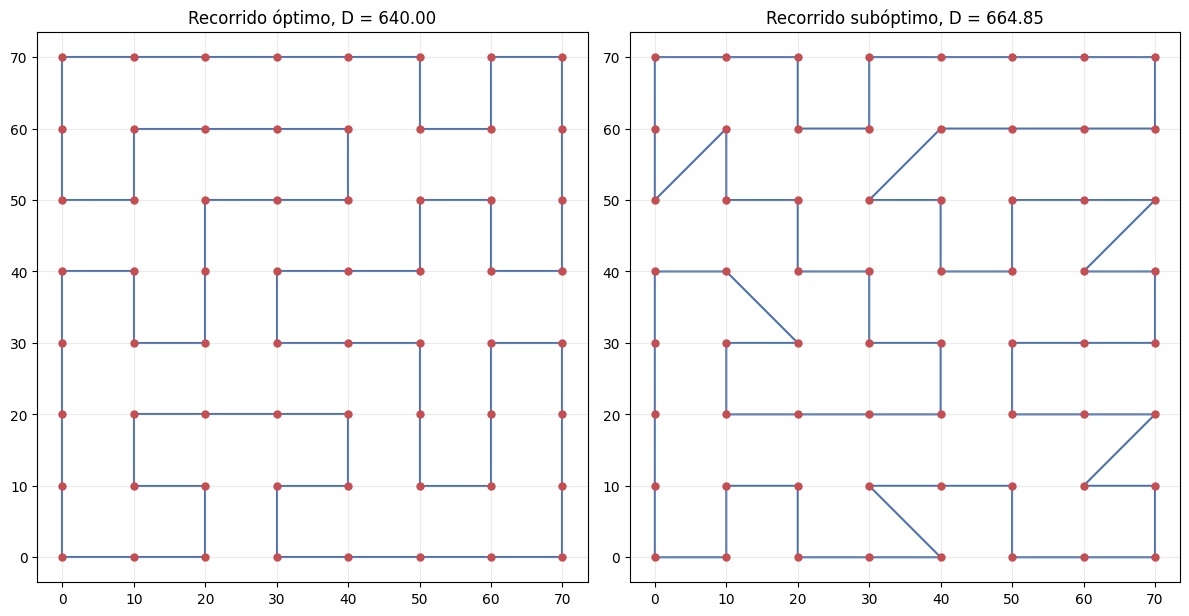

Aristas largas del óptimo:    []
Aristas largas del subóptimo: [14.14 14.14 14.14 14.14 14.14 14.14]


In [9]:
# El recorrido óptimo de la corrida principal, junto a un recorrido subóptimo de la primera configuración
primera = corridas["N = 300, 1500 generaciones"]
peor = max(primera, key=lambda r: r[1])
mejor = (best, D)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 6))
dibujar_recorrido(a1, ciudades, mejor[0], f"Recorrido óptimo, D = {mejor[1]:.2f}")
dibujar_recorrido(a2, ciudades, peor[0], f"Recorrido subóptimo, D = {peor[1]:.2f}")
plt.tight_layout()
plt.savefig("optimo_vs_suboptimo.png", dpi=200)
plt.show()

# Aristas de más de 10 unidades de cada recorrido
def largas(recorrido):
    d = matriz_de_distancias(ciudades)
    pasos = d[recorrido, np.roll(recorrido, -1)]
    return np.round(pasos[pasos > SEPARACION + 1e-9], 2)

print("Aristas largas del óptimo:   ", largas(mejor[0]))
print("Aristas largas del subóptimo:", largas(peor[0]))

### Explicación de esta parte

La tabla resume las 8 corridas de cada configuración y la gráfica muestra todas las curvas con su mediana. Las corridas subóptimas se quedan en valores como 648.28 o 656.57, que son el óptimo más una o dos diagonales de 14.14 que reemplazan tramos de 10.

## Conclusión

Con la cuadrícula de 8 por 8 se pudo comparar el resultado del algoritmo genético con un óptimo que se conoce de antemano, que es 640. El algoritmo bajó la distancia desde un recorrido al azar hasta el óptimo o muy cerca de él.